# 03 · Modelos
Tarea (a): MLP vs. regresión logística y LightGBM (S1, S8). Tarea (b): LSTM de alerta temprana (S3) vs. baselines. Entrenamiento: `python -m worldsim.train.run_task_a` y `python -m worldsim.train.run_task_b`.

In [1]:
import os, sys
os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())
sys.path.insert(0, "src")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.options.display.float_format = "{:.4f}".format

## Tarea (a): condiciones iniciales → supervivencia (test, 7 500 planetas)

,Modelo,ROC-AUC,PR-AUC,F1,Brier,ECE,MAE vs P_verdadera (MC)
0,Regresión logística,0.6324,0.7412,0.7583,0.2229,0.0183,0.3950
1,LightGBM,0.9809,0.9886,0.9439,0.0524,0.0199,0.0665
2,MLP,0.9868,0.9924,0.9487,0.0443,0.0078,0.0342


mejores hiperparámetros MLP: {'hidden': [128, 64], 'dropout': 0.2, 'lr': 0.001, 'weight_decay': 0.1}


,hp,val_bce,epochs,sec
6,"{'hidden': [128, 64], 'dropout': 0.2, 'lr': 0....",0.1425,113,12.5400
1,"{'hidden': [128, 64], 'dropout': 0.1, 'lr': 0....",0.1426,200,22.6739
11,"{'hidden': [128, 64], 'dropout': 0.2, 'lr': 0....",0.1428,66,7.4648
4,"{'hidden': [256, 128, 64], 'dropout': 0.2, 'lr...",0.1442,103,13.7507
3,"{'hidden': [256, 128], 'dropout': 0.3, 'lr': 0...",0.1447,39,4.2941


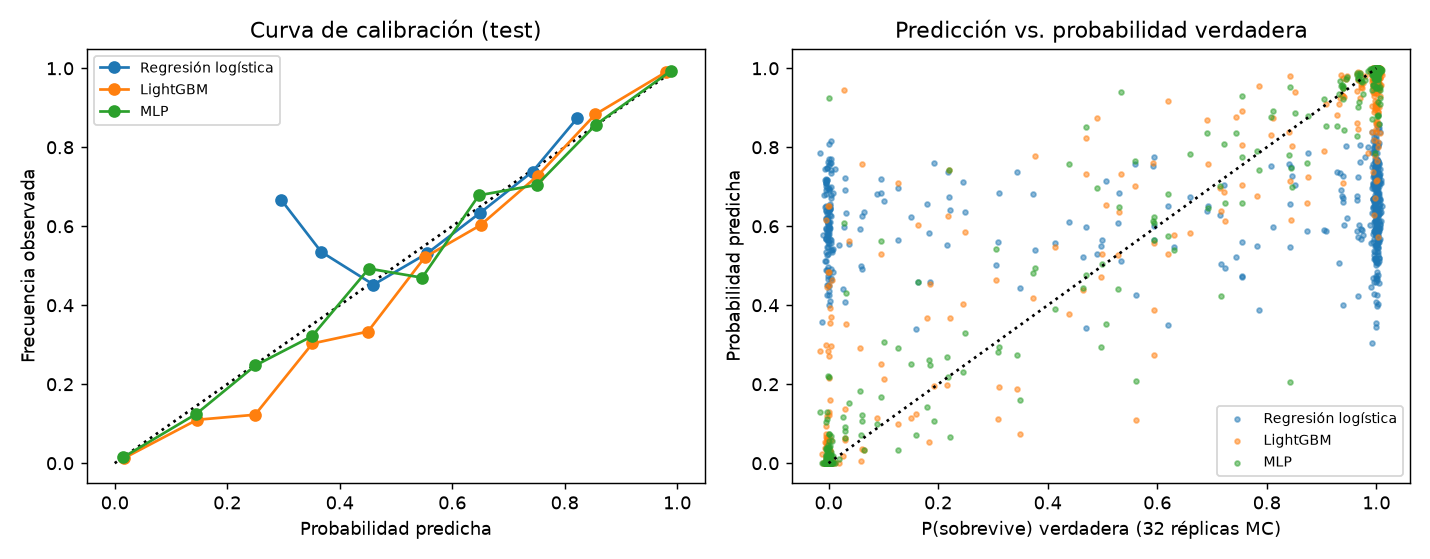

In [2]:
import json
from worldsim.reporting import task_a_tables, task_b_tables
ta = task_a_tables(); display(ta)
r = json.load(open('outputs/task_a/results.json')); print('mejores hiperparámetros MLP:', r['best_hp'])
display(pd.DataFrame(r['trials']).sort_values('val_bce').head(5))
display(Image('report/figures/fig_tarea_a_calibracion.png'))

## Tarea (b): primeros k% de la trayectoria → supervivencia
Solo se evalúan planetas aún vivos al final de la ventana; se reporta cuántos quedan fuera.

ROC-AUC


,LSTM (con parámetros),LSTM (sin parámetros),LightGBM (parámetros + resumen),MLP (ventana aplanada),MLP solo parámetros (tarea a)
0%,0.9737,0.5268,0.9806,0.9870,0.9868
5%,0.9859,0.9350,0.9834,0.9858,0.9868
10%,0.9858,0.9540,0.9833,0.9848,0.9859
20%,0.9833,0.9544,0.9798,0.9811,0.9824
40%,0.9860,0.9748,0.9854,0.9827,0.9792
60%,0.9884,0.9848,0.9875,0.9840,0.9731


Brier


,LSTM (con parámetros),LSTM (sin parámetros),LightGBM (parámetros + resumen),MLP (ventana aplanada),MLP solo parámetros (tarea a)
0%,0.0689,0.2341,0.0528,0.0440,0.0443
5%,0.0473,0.0994,0.0495,0.0462,0.0443
10%,0.0464,0.0828,0.0492,0.0468,0.0453
20%,0.0478,0.0792,0.0518,0.0494,0.0488
40%,0.0416,0.0550,0.0423,0.0459,0.0508
60%,0.0276,0.0308,0.0287,0.0312,0.0470


Planetas excluidos (ya colapsados en la ventana)


,Planetas test,Evaluados (vivos),Excluidos,Supervivencia entre vivos
0%,7500,7500,0,0.6265
5%,7500,7500,0,0.6265
10%,7500,7329,171,0.6412
20%,7500,6775,725,0.6936
40%,7500,6396,1104,0.7347
60%,7500,5430,2070,0.8654


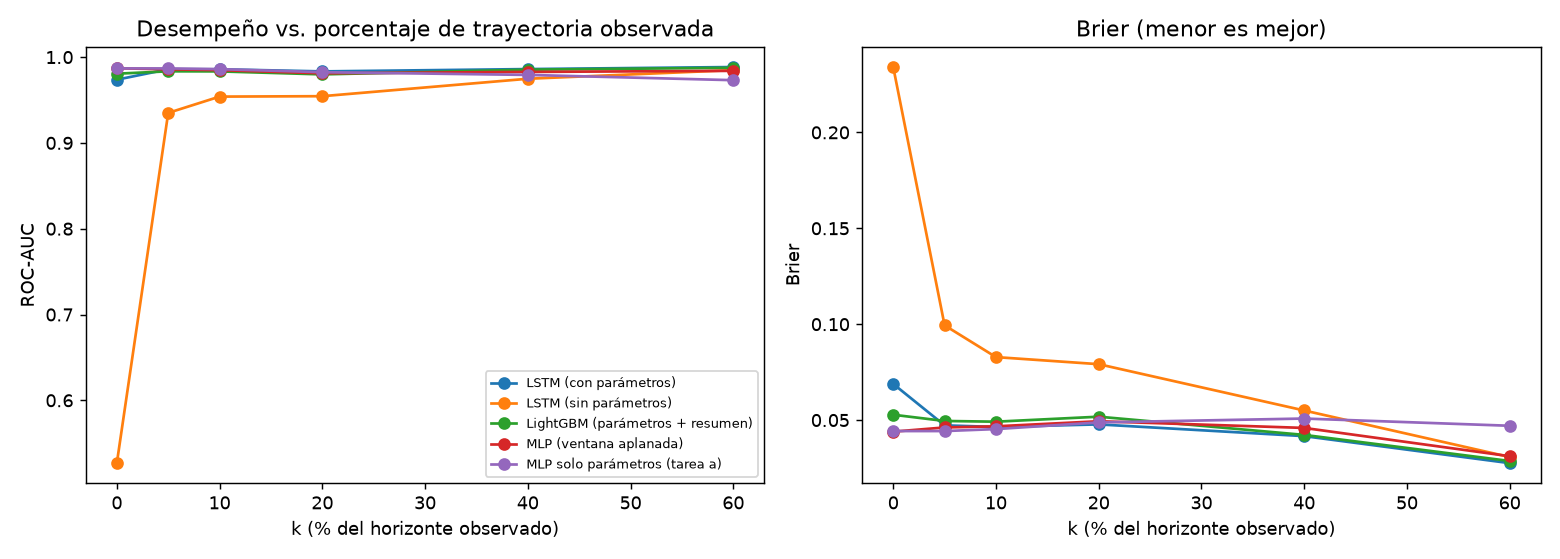

In [3]:
auc, brier, excl = task_b_tables()
print('ROC-AUC'); display(auc); print('Brier'); display(brier); print('Planetas excluidos (ya colapsados en la ventana)'); display(excl)
display(Image('report/figures/fig_tarea_b_curva_k.png'))